Nome: Douglas Patriota Lopes

In [11]:
from collections import deque # Importa o deque para obter alta performance na fila da BFS (O(1) para remover elementos do início)

# Representação da malha aérea (Lista de Adjacência)
grafo = {
 "Brasília": ["Goiânia", "Belo Horizonte"],
 "Goiânia": ["Brasília", "São Paulo", "Cuiabá"],
 "Belo Horizonte": ["Brasília", "Rio de Janeiro"],
 "São Paulo": ["Goiânia", "Curitiba", "Rio de Janeiro"],
 "Cuiabá": ["Goiânia", "Curitiba"],
 "Rio de Janeiro": ["Belo Horizonte", "São Paulo", "Curitiba"],
 "Curitiba": ["São Paulo", "Cuiabá", "Rio de Janeiro"]
}

# Algoritmo de Busca em Largura (BFS) - Busca caminhos mínimos por níveis/escalas
def bfs(rede, origem, destino):
    # Inicializa a fila contendo tuplas com (nó_atual, caminho_percorrido_até_ele)
    fila = deque([(origem, [origem])])
    # Cria um conjunto de nós visitados para evitar loops de processamento duplicado
    visitados = {origem}

    # Loop continua enquanto houverem nós a serem explorados na fila
    while fila:
        # Retira o primeiro nó que entrou na fila (Princípio FIFO)
        atual, caminho = fila.popleft()
        # Se atingiu o destino final, retorna o caminho acumulado correspondente
        if atual == destino:
            return caminho
        # Explora os nós conectados diretamente ao nó atual
        for vizinho in rede.get(atual, []):
            # Se o nó vizinho ainda não foi visitado no trajeto atual
            if vizinho not in visitados:
                # Adiciona ao conjunto de visitados
                visitados.add(vizinho)
                # Insere o vizinho no fim da fila atualizando o caminho histórico percorrido
                fila.append((vizinho, caminho + [vizinho]))
    return None # Retorna None se não houver nenhuma conexão possível entre os dois nós

# Algoritmo de Busca em Profundidade (DFS) - Explora ao máximo cada ramo antes de retroceder
def dfs(rede, origem, destino):
    # Inicializa a pilha contendo tuplas com (nó_atual, caminho_percorrido_até_ele)
    pilha = [(origem, [origem])]
    # Cria um conjunto vazio para registrar os nós cujos caminhos já foram consolidados
    visitados = set()

    # Executa o loop enquanto houverem elementos na pilha
    while pilha:
        # Retira o elemento mais recentemente inserido no topo da pilha (Princípio LIFO)
        atual, caminho = pilha.pop()
        # Ignora se o nó já tiver sido completamente explorado e visitado
        if atual in visitados:
            continue
        # Marca o nó atual como visitado na busca
        visitados.add(atual)
        # Se atingiu o destino, retorna imediatamente o caminho
        if atual == destino:
            return caminho
        # Explora os vizinhos de forma inversa para garantir a ordem natural de pilha
        for vizinho in reversed(rede.get(atual, [])):
            if vizinho not in visitados:
                # Empilha o vizinho atualizando o caminho acumulado até ele
                pilha.append((vizinho, caminho + [vizinho]))
    return None # Retorna None se não encontrar conectividade física entre origem e destino

# Função para bloquear uma conexão simulada entre duas cidades (Grafo não-direcionado)
def bloquear_conexao(rede, a, b):
    # Cria uma cópia rasa/individual das conexões para preservar o grafo original
    copia = {no: vizinhos.copy() for no, vizinhos in rede.items()}
    # Remove o nó 'b' da lista de vizinhos do nó 'a' se ele existir
    if b in copia.get(a, []):
        copia[a].remove(b)
    # Remove o nó 'a' da lista de vizinhos do nó 'b' se ele existir (mão dupla)
    if a in copia.get(b, []):
        copia[b].remove(a)
    return copia # Retorna o novo grafo modificado com a barreira aérea criada

# Execução e testes das simulações
origem, destino = "Brasília", "Curitiba"
for nome, rede in [("Normal", grafo),
                   ("Bloqueio Goiânia–São Paulo", bloquear_conexao(grafo, "Goiânia", "São Paulo"))]:
    print("\nCenário:", nome)
    print("BFS:", bfs(rede, origem, destino))
    print("DFS:", dfs(rede, origem, destino))


Cenário: Normal
BFS: ['Brasília', 'Goiânia', 'São Paulo', 'Curitiba']
DFS: ['Brasília', 'Goiânia', 'São Paulo', 'Curitiba']

Cenário: Bloqueio Goiânia–São Paulo
BFS: ['Brasília', 'Goiânia', 'Cuiabá', 'Curitiba']
DFS: ['Brasília', 'Goiânia', 'Cuiabá', 'Curitiba']


In [13]:
from collections import deque

# 1. Grafo reconstruído com base EXATA na imagem fornecida (IATA codes)
grafo_aeroportos = {
    "BSB": ["GYN", "CNF"],
    "GYN": ["BSB", "GRU", "CGB"],
    "CNF": ["BSB", "GIG"],
    "GRU": ["GYN", "CWB", "GIG"],
    "CGB": ["GYN", "CWB"],
    "GIG": ["CNF", "GRU", "CWB"],
    "CWB": ["GRU", "CGB", "GIG"]
}

# 2. Implementação do algoritmo BFS
def bfs(rede, origem, destino):
    fila = deque([(origem, [origem])])
    visitados = {origem}
    while fila:
        atual, caminho = fila.popleft()
        if atual == destino:
            return caminho
        for vizinho in rede.get(atual, []):
            if vizinho not in visitados:
                visitados.add(vizinho)
                fila.append((vizinho, caminho + [vizinho]))
    return None

# 3. Implementação do algoritmo DFS
def dfs(rede, origem, destino):
    pilha = [(origem, [origem])]
    visitados = set()
    while pilha:
        atual, caminho = pilha.pop()
        if atual in visitados:
            continue
        visitados.add(atual)
        if atual == destino:
            return caminho
        for vizinho in reversed(rede.get(atual, [])):
            if vizinho not in visitados:
                pilha.append((vizinho, caminho + [vizinho]))
    return None

# 4. Função para bloquear COMPLETAMENTE um aeroporto (nó e todas as suas arestas)
def bloquear_aeroporto(rede, aeroporto_bloqueado):
    # Cria uma cópia profunda para não modificar o grafo original
    copia = {no: vizinhos.copy() for no, vizinhos in rede.items()}

    # Remove o nó bloqueado e limpa as referências a ele em outros nós
    if aeroporto_bloqueado in copia:
        copia[aeroporto_bloqueado] = []  # Isola o aeroporto bloqueado

    for no in copia:
        if aeroporto_bloqueado in copia[no]:
            copia[no].remove(aeroporto_bloqueado)

    return copia

# 5. Interface Interativa com Validação
def obter_aeroporto_valido(mensagem, rede):
    while True:
        aeroporto = input(mensagem).strip().upper()
        if aeroporto in rede:
            return aeroporto
        print(f"❌ Erro: '{aeroporto}' não faz parte da nossa malha aérea. Aeroportos disponíveis: {list(rede.keys())}\n")

print("=== SISTEMA INTERATIVO DE ROTAS AÉREAS (MAPA DA IMAGEM) ===")
print(f"Aeroportos na rede: {', '.join(grafo_aeroportos.keys())}\n")

# Entrada de dados do usuário
origem = obter_aeroporto_valido("Digite o aeroporto de origem (ex: GYN): ", grafo_aeroportos)
destino = obter_aeroporto_valido("Digite o aeroporto de destino (ex: CWB): ", grafo_aeroportos)

# Simulação compulsória ou opcional do bloqueio de Brasília (BSB)
print("\n⚠️ Aplicando bloqueio operacional completo no aeroporto de Brasília (BSB)...")
rede_ativa = bloquear_aeroporto(grafo_aeroportos, "BSB")

# 6. Execução das buscas e exibição dos resultados alternativos
print(f"\nBuscando rota de '{origem}' para '{destino}' (Evitando BSB):")

for nome_alg, alg in [("Busca em Largura (BFS)", bfs), ("Busca em Profundidade (DFS)", dfs)]:
    caminho = alg(rede_ativa, origin, destino) if 'origin' in locals() else alg(rede_ativa, origem, destino)
    print(f"\n[{nome_alg}]")

    if caminho is None:
        print(f"❌ Não há nenhuma rota viável disponível entre {origem} e {destino} com o fechamento de BSB.")
    else:
        total_arestas = len(caminho) - 1
        print(f"🟢 Rota alternativa encontrada: {' -> '.join(caminho)}")
        print(f"📊 Quantidade de trechos (voos): {total_arestas} (com {total_arestas - 1} conexão/ões)")


=== SISTEMA INTERATIVO DE ROTAS AÉREAS (MAPA DA IMAGEM) ===
Aeroportos na rede: BSB, GYN, CNF, GRU, CGB, GIG, CWB

Digite o aeroporto de origem (ex: GYN): CWB
Digite o aeroporto de destino (ex: CWB): GIG

⚠️ Aplicando bloqueio operacional completo no aeroporto de Brasília (BSB)...

Buscando rota de 'CWB' para 'GIG' (Evitando BSB):

[Busca em Largura (BFS)]
🟢 Rota alternativa encontrada: CWB -> GIG
📊 Quantidade de trechos (voos): 1 (com 0 conexão/ões)

[Busca em Profundidade (DFS)]
🟢 Rota alternativa encontrada: CWB -> GRU -> GIG
📊 Quantidade de trechos (voos): 2 (com 1 conexão/ões)


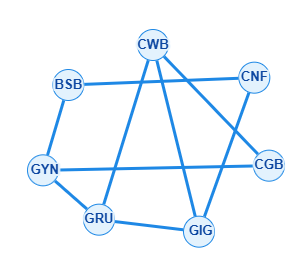

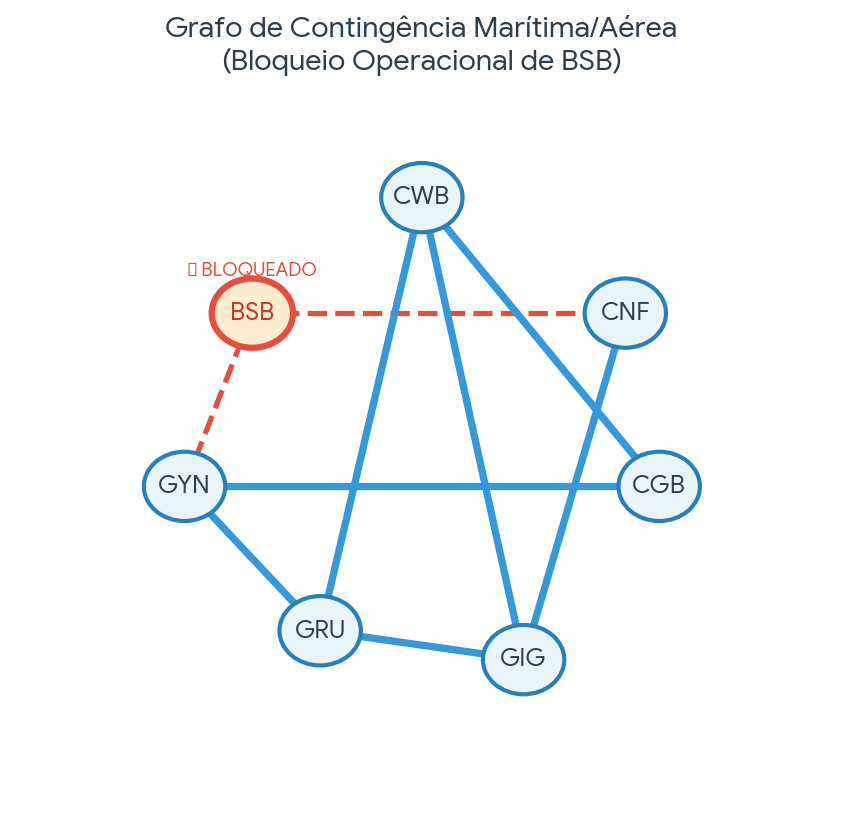